In [0]:
%pip install tensorflow

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 281.9/281.9 MB 176.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.7/4.7 MB 136.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 89.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.8/23.8 MB 172.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.0/5.0 MB 123.9 MB/s eta 0:00:00
  Attempting uninstall: protobuf
    Found existing installation: protobuf 5.29.4
    Not uninstalling protobuf at /databricks/python3/lib/python3.12/site-packages, outside environment /local_disk0/.ephemeral_nfs/envs/pythonEnv-aa14c6d0-fc6c-4ac5-be4f-c9ab59ce76ce
    Can't uninstall 'protobuf'. No files were found to uninstall.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-api-core 2.28.1 requires protobuf!=3.20.0,!=3.20.1,!=4.21.0,!=4.21.1,!=4.21.2,!=4.21.3,!=4.21

In [0]:
import pandas as pd

# O novo caminho moderno usando Unity Catalog (Volumes)
caminho_nuvem = "/Volumes/workspace/default/meu_volume/dataset_mestre_pld.csv"

print("📡 Puxando os dados do Volume da nuvem usando o motor Serverless...")
try:
    df_nuvem = pd.read_csv(caminho_nuvem, index_col='DATA_HORA', parse_dates=True)
    print(f"✅ Base de Dados carregada com sucesso no Databricks! Total de linhas: {len(df_nuvem)}")
    display(df_nuvem.head())
except FileNotFoundError:
    print("🚨 Arquivo não encontrado! Verifique se o nome do arquivo subiu corretamente e copie o caminho exato do botão 'Copy path' no Databricks.")

📡 Puxando os dados do Volume da nuvem usando o motor Serverless...
✅ Base de Dados carregada com sucesso no Databricks! Total de linhas: 43824


PLD,CARGA_MWMED,ENA_MWMED,EAR_PERCENTUAL
204.37,33498.352,41167.16015625,18.95179939
206.82,33183.00599999,41167.16015625,18.95179939
204.61,32630.701,41167.16015625,18.95179939
209.2,31738.47,41167.16015625,18.95179939
207.19,31233.24299999,41167.16015625,18.95179939


In [0]:
from sklearn.preprocessing import MinMaxScaler
import pandas as pd

print("🔄 Recriando a Memória Temporal e o Nivelamento na Nuvem...")

# 1. Pegamos a base bruta que já está no Databricks
df_modelo = df_nuvem.copy()

# 2. Injetando a Memória (Lags)
lags_pld = [1, 2, 3, 24] 
lags_carga = [1, 24]

for lag in lags_pld:
    df_modelo[f'PLD_lag_{lag}'] = df_modelo['PLD'].shift(lag)
for lag in lags_carga:
    df_modelo[f'CARGA_lag_{lag}'] = df_modelo['CARGA_MWMED'].shift(lag)

df_modelo['ENA_lag_24'] = df_modelo['ENA_MWMED'].shift(24)
df_modelo['EAR_lag_24'] = df_modelo['EAR_PERCENTUAL'].shift(24)

# Sacrificando as 24 primeiras horas vazias
df_modelo = df_modelo.dropna()

# 3. O Corte Cronológico (Evitando Data Leakage)
df_treino = df_modelo[df_modelo.index.year <= 2023].copy()
df_validacao = df_modelo[df_modelo.index.year == 2024].copy()
df_teste = df_modelo[df_modelo.index.year >= 2025].copy()

# 4. O Nivelamento de Poder (MinMaxScaler)
alvo = ['PLD']
features = [col for col in df_modelo.columns if col not in alvo]

scaler_X = MinMaxScaler()
scaler_Y = MinMaxScaler()

# Treinando a régua só no Treino e aplicando no resto
df_treino[features] = scaler_X.fit_transform(df_treino[features])
df_treino[alvo] = scaler_Y.fit_transform(df_treino[alvo])

df_validacao[features] = scaler_X.transform(df_validacao[features])
df_validacao[alvo] = scaler_Y.transform(df_validacao[alvo])

df_teste[features] = scaler_X.transform(df_teste[features])
df_teste[alvo] = scaler_Y.transform(df_teste[alvo])

print("✅ Fase 4 recriada com sucesso! O df_treino está na memória e pronto para a IA.")
print(f"Total de variáveis (Features) para o modelo aprender: {len(features)}")

🔄 Recriando a Memória Temporal e o Nivelamento na Nuvem...
✅ Fase 4 recriada com sucesso! O df_treino está na memória e pronto para a IA.
Total de variáveis (Features) para o modelo aprender: 11


In [0]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout, Input

print("🧠 Forjando a Arquitetura da Rede Neural LSTM...")

# 1. Definindo o modelo Sequencial (um bloco atrás do outro)
modelo_pld = Sequential()

# 2. A Camada de Entrada
# O 'shape' (formato) será definido pelo número de passos no tempo (timesteps) e o número de variáveis (features) que preparamos na Fase 4.
# Por enquanto, deixamos as variáveis genéricas (timesteps, features)
timesteps = 1 
features = df_treino[features].shape[1] # Número de colunas exógenas e lags que criamos

modelo_pld.add(Input(shape=(timesteps, features)))

# 3. Primeira Camada LSTM (A Memória Principal)
# return_sequences=True é obrigatório porque vamos passar a memória para outra LSTM logo abaixo
modelo_pld.add(LSTM(units=64, return_sequences=True, activation='tanh'))

# 4. Camada de Dropout (O Segurança contra a decoreba)
# Desliga aleatoriamente 20% dos neurônios a cada rodada de treino
modelo_pld.add(Dropout(rate=0.2))

# 5. Segunda Camada LSTM (Refinamento)
# return_sequences=False porque agora ela vai mandar os dados para uma camada normal (Dense)
modelo_pld.add(LSTM(units=32, return_sequences=False, activation='tanh'))

# mais um pouco de Dropout por segurança
modelo_pld.add(Dropout(rate=0.2))

# 6. Camada Densa (Processamento das informações mastigadas)
modelo_pld.add(Dense(units=16, activation='relu'))

# 7. Camada de Saída (O Alvo)
# 1 único neurônio, pois queremos prever 1 único valor: O preço do PLD na próxima hora
modelo_pld.add(Dense(units=1, activation='linear'))

print("✅ Cérebro instanciado com sucesso!")
print("-" * 60)
# Isso vai imprimir um resumo visual de quantos milhares de parâmetros (sinapses) sua rede tem
modelo_pld.summary()

🧠 Forjando a Arquitetura da Rede Neural LSTM...
✅ Cérebro instanciado com sucesso!
------------------------------------------------------------


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 1, 64)          │        19,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1, 64)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 32,417 (126.63 KB)

 Trainable params: 32,417 (126.63 KB)

 Non-trainable params: 0 (0.00 B)

In [0]:
import numpy as np

print("🧊 Restaurando a lista de variáveis e Forjando os Tensores 3D...")

# 1. A CURA: Recriando a lista de nomes das colunas (ignorando o PLD)
alvo = ['PLD']
features = [col for col in df_treino.columns if col not in alvo]

# 2. Separando o 'X' (As Dicas/Features) do 'Y' (A Resposta/PLD)
X_treino = df_treino[features].values
Y_treino = df_treino[alvo].values

X_validacao = df_validacao[features].values
Y_validacao = df_validacao[alvo].values

X_teste = df_teste[features].values
Y_teste = df_teste[alvo].values

# 3. A Dobra Espacial (Reshape 2D -> 3D)
timesteps = 1
# Usando um nome diferente agora para não sobrescrever a lista de novo! kkkk
qtd_features = X_treino.shape[1] 

# Redimensionando: (Amostras, 1 Passo, Colunas)
X_treino_3D = X_treino.reshape((X_treino.shape[0], timesteps, qtd_features))
X_validacao_3D = X_validacao.reshape((X_validacao.shape[0], timesteps, qtd_features))
X_teste_3D = X_teste.reshape((X_teste.shape[0], timesteps, qtd_features))

print("✅ Transformação Concluída com Sucesso sem bugs!")
print("-" * 60)
print(f"Novo Formato do Treino (3D):   {X_treino_3D.shape} 🧊")
print(f"Novo Formato da Validação (3D): {X_validacao_3D.shape} 🧊")
print("-" * 60)
print("⛽ O combustível está perfeitamente refinado e pronto para o motor!")

🧊 Restaurando a lista de variáveis e Forjando os Tensores 3D...
✅ Transformação Concluída com Sucesso sem bugs!
------------------------------------------------------------
Novo Formato do Treino (3D):   (26256, 1, 11) 🧊
Novo Formato da Validação (3D): (8784, 1, 11) 🧊
------------------------------------------------------------
⛽ O combustível está perfeitamente refinado e pronto para o motor!


In [0]:
from tensorflow.keras.callbacks import EarlyStopping

print("⚙️ Compilando o motor da Rede Neural...")

# 1. COMPILAÇÃO
# O Otimizador 'adam' é o algoritmo matemático que ajusta os pesos.
# O Loss 'mse' (Erro Quadrático Médio) é a métrica que a IA tenta reduzir a todo custo.
modelo_pld.compile(optimizer='adam', loss='mse', metrics=['mae'])

# 2. O FREIO DE EMERGÊNCIA (Early Stopping)
# Se a métrica na Validação não melhorar por 5 ciclos (patience), o treino para.
early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

print("🚀 INICIANDO O TREINAMENTO (Pode pegar um café, o motor vai roncar!)...")
print("-" * 60)

# 3. O TREINAMENTO (FIT)
# epochs=50: A IA vai ler os 3 anos de história 50 vezes.
# batch_size=64: Ela lê pacotes de 64 horas por vez antes de ajustar as sinapses.
historico = modelo_pld.fit(
    X_treino_3D, Y_treino,
    validation_data=(X_validacao_3D, Y_validacao),
    epochs=50,
    batch_size=64,
    callbacks=[early_stop],
    verbose=1 # Mostra a barra de progresso!
)

print("-" * 60)
print("🏆 TREINAMENTO CONCLUÍDO! O cérebro aprendeu os padrões do PLD!")

⚙️ Compilando o motor da Rede Neural...
🚀 INICIANDO O TREINAMENTO (Pode pegar um café, o motor vai roncar!)...
------------------------------------------------------------
Epoch 1/50
411/411 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - loss: 3.7038e-04 - mae: 0.0104 - val_loss: 0.0033 - val_mae: 0.0155
Epoch 2/50
411/411 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 3.5871e-04 - mae: 0.0101 - val_loss: 0.0032 - val_mae: 0.0133
Epoch 3/50
411/411 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - loss: 3.5378e-04 - mae: 0.0099 - val_loss: 0.0033 - val_mae: 0.0136
Epoch 4/50
411/411 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 3.5189e-04 - mae: 0.0098 - val_loss: 0.0032 - val_mae: 0.0132
Epoch 5/50
411/411 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 3.5009e-04 - mae: 0.0097 - val_loss: 0.0032 - val_mae: 0.0136
Epoch 6/50
411/411 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - loss: 3.3953e-04 - mae: 0.0092 - val_loss: 0.0034 - val_mae: 0.0195
Epoch 7/50
411/411 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 3.4685e-04 - mae: 0.0095 - val_loss:

🔮 Prevendo o futuro: Injetando os dados de 2025 na IA...
274/274 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
✅ Previsões concluídas e convertidas de volta para Reais (R$)!
------------------------------------------------------------


/databricks/python/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 128302 (\N{CRYSTAL BALL}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


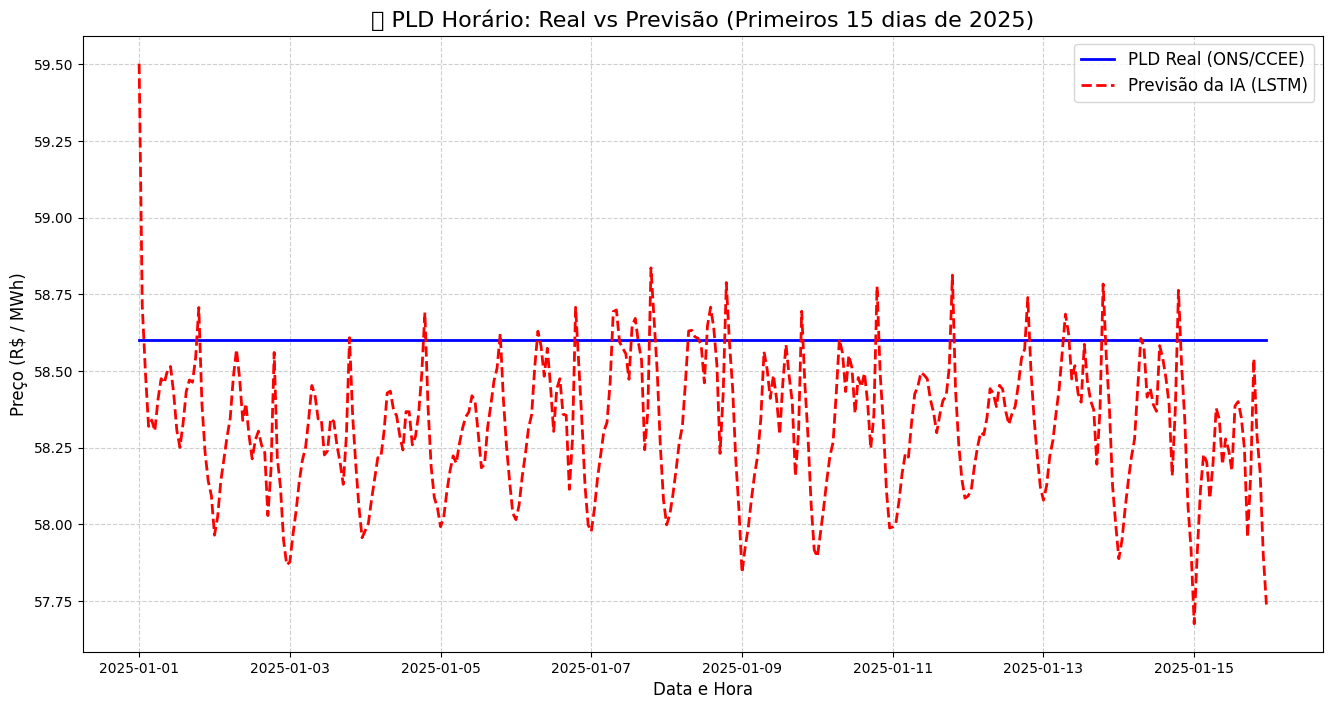

In [0]:
import matplotlib.pyplot as plt
import pandas as pd

print("🔮 Prevendo o futuro: Injetando os dados de 2025 na IA...")

# 1. Fazendo as previsões com o tensor de Teste (Cálculo matemático entre 0 e 1)
previsoes_normalizadas = modelo_pld.predict(X_teste_3D)

# 2. Desfazendo a normalização (Transformando de 0-1 de volta para R$)
previsoes_reais = scaler_Y.inverse_transform(previsoes_normalizadas)
valores_reais = scaler_Y.inverse_transform(Y_teste)

# 3. Criando um DataFrame para organizar o combate (Real vs Previsto)
df_resultado = pd.DataFrame({
    'Data': df_teste.index,
    'PLD_Real': valores_reais.flatten(),
    'PLD_Previsto': previsoes_reais.flatten()
})
df_resultado.set_index('Data', inplace=True)

print("✅ Previsões concluídas e convertidas de volta para Reais (R$)!")
print("-" * 60)

# 4. Plotando o Gráfico de Batalha!
plt.figure(figsize=(16, 8))

# Vamos plotar apenas os primeiros 15 dias (360 horas) de 2025 
# Se plotarmos o ano inteiro, as linhas ficam tão espremidas que não dá para ver nada
dias_para_mostrar = 360 

plt.plot(df_resultado.index[:dias_para_mostrar], df_resultado['PLD_Real'][:dias_para_mostrar], 
         label='PLD Real (ONS/CCEE)', color='blue', linewidth=2)
         
plt.plot(df_resultado.index[:dias_para_mostrar], df_resultado['PLD_Previsto'][:dias_para_mostrar], 
         label='Previsão da IA (LSTM)', color='red', linestyle='dashed', linewidth=2)

plt.title('🔮 PLD Horário: Real vs Previsão (Primeiros 15 dias de 2025)', fontsize=16)
plt.xlabel('Data e Hora', fontsize=12)
plt.ylabel('Preço (R$ / MWh)', fontsize=12)
plt.legend(fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

⚖️ Aplicando a Regra de Negócio (Trava da ANEEL)...
✅ Trava regulatória aplicada! Plotando o gráfico final corrigido...
------------------------------------------------------------


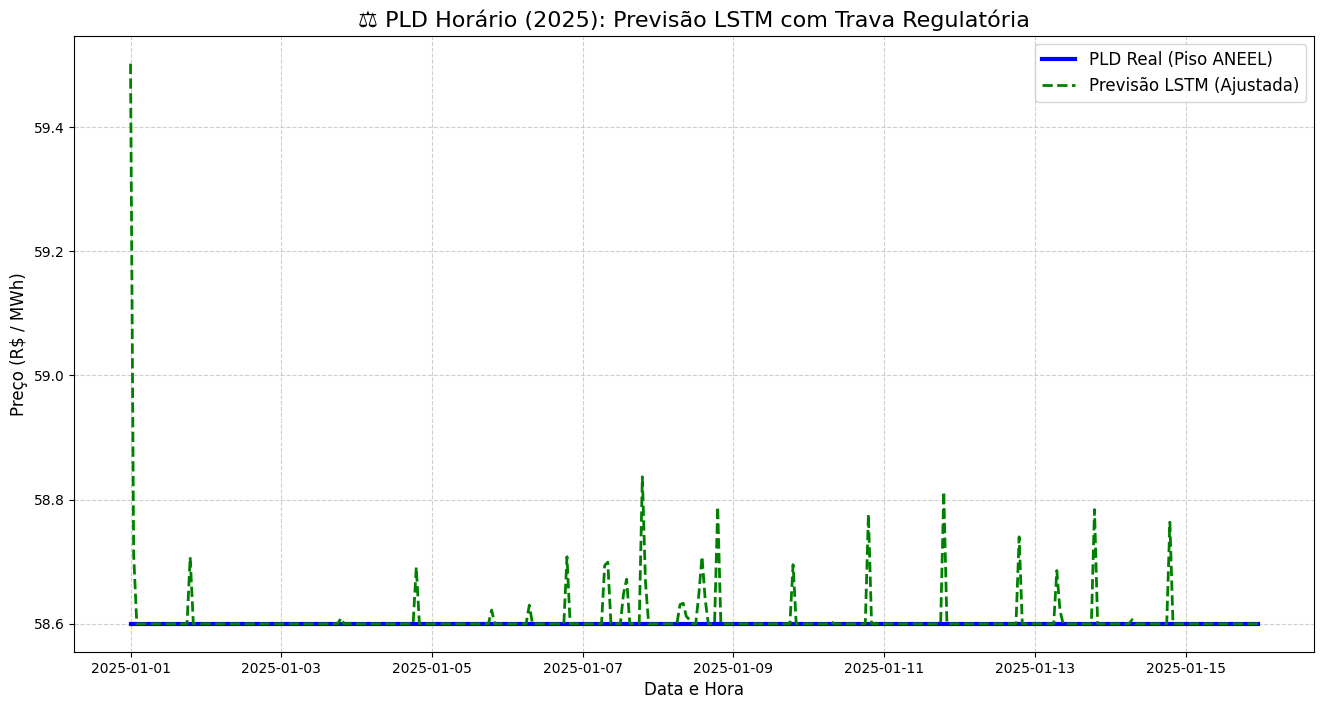

In [0]:
import numpy as np
import matplotlib.pyplot as plt

print("⚖️ Aplicando a Regra de Negócio (Trava da ANEEL)...")

# O Piso estabelecido pela ANEEL para o ano de 2025
piso_pld_2025 = 58.60

# Aplicando o Clipping (se for menor que o piso, vira o piso)
df_resultado['PLD_Previsto_Ajustado'] = np.clip(df_resultado['PLD_Previsto'], a_min=piso_pld_2025, a_max=None)

print("✅ Trava regulatória aplicada! Plotando o gráfico final corrigido...")
print("-" * 60)

# Plotando o Gráfico Corrigido
plt.figure(figsize=(16, 8))
dias_para_mostrar = 360 

plt.plot(df_resultado.index[:dias_para_mostrar], df_resultado['PLD_Real'][:dias_para_mostrar], 
         label='PLD Real (Piso ANEEL)', color='blue', linewidth=3)
         
plt.plot(df_resultado.index[:dias_para_mostrar], df_resultado['PLD_Previsto_Ajustado'][:dias_para_mostrar], 
         label='Previsão LSTM (Ajustada)', color='green', linestyle='dashed', linewidth=2)

plt.title('⚖️ PLD Horário (2025): Previsão LSTM com Trava Regulatória', fontsize=16)
plt.xlabel('Data e Hora', fontsize=12)
plt.ylabel('Preço (R$ / MWh)', fontsize=12)
plt.legend(fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

⚖️ Aplicando a Regra de Negócio Avançada (Banda de Saturação)...


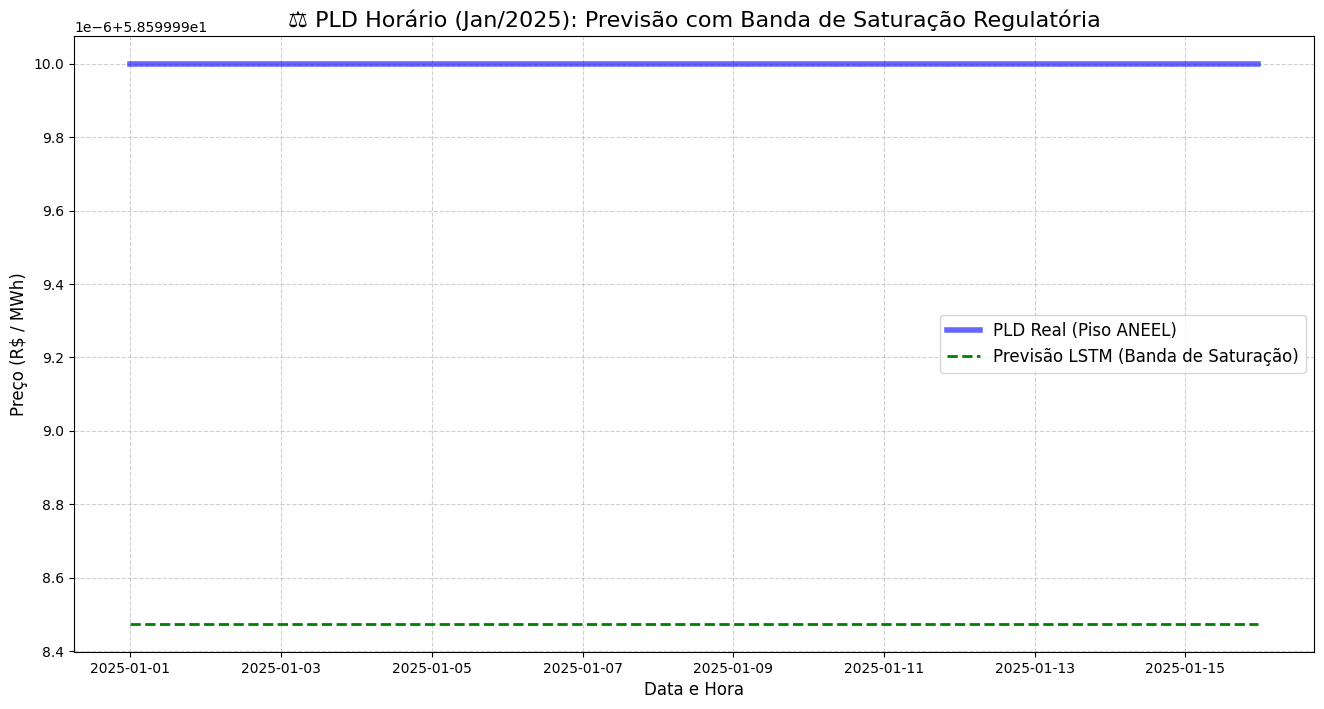

In [0]:
import numpy as np
import matplotlib.pyplot as plt

print("⚖️ Aplicando a Regra de Negócio Avançada (Banda de Saturação)...")

piso_pld_2025 = 58.60
margem_tolerancia = 8.00 # Margem de 8 reais

# Regra: Se a previsão for menor ou igual ao (Piso + Tolerância), crava no Piso. 
# Se for maior, mantém a previsão original da IA.
df_resultado['PLD_Previsto_Final'] = np.where(
    df_resultado['PLD_Previsto'] <= (piso_pld_2025 + margem_tolerancia),
    piso_pld_2025,
    df_resultado['PLD_Previsto']
)

# Plotando o Gráfico Corrigido
plt.figure(figsize=(16, 8))
dias_para_mostrar = 360 

plt.plot(df_resultado.index[:dias_para_mostrar], df_resultado['PLD_Real'][:dias_para_mostrar], 
         label='PLD Real (Piso ANEEL)', color='blue', linewidth=4, alpha=0.6)
         
plt.plot(df_resultado.index[:dias_para_mostrar], df_resultado['PLD_Previsto_Final'][:dias_para_mostrar], 
         label='Previsão LSTM (Banda de Saturação)', color='green', linestyle='dashed', linewidth=2)

plt.title('⚖️ PLD Horário (Jan/2025): Previsão com Banda de Saturação Regulatória', fontsize=16)
plt.xlabel('Data e Hora', fontsize=12)
plt.ylabel('Preço (R$ / MWh)', fontsize=12)
plt.legend(fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

🎨 Desativando o zoom microscópico do Matplotlib...


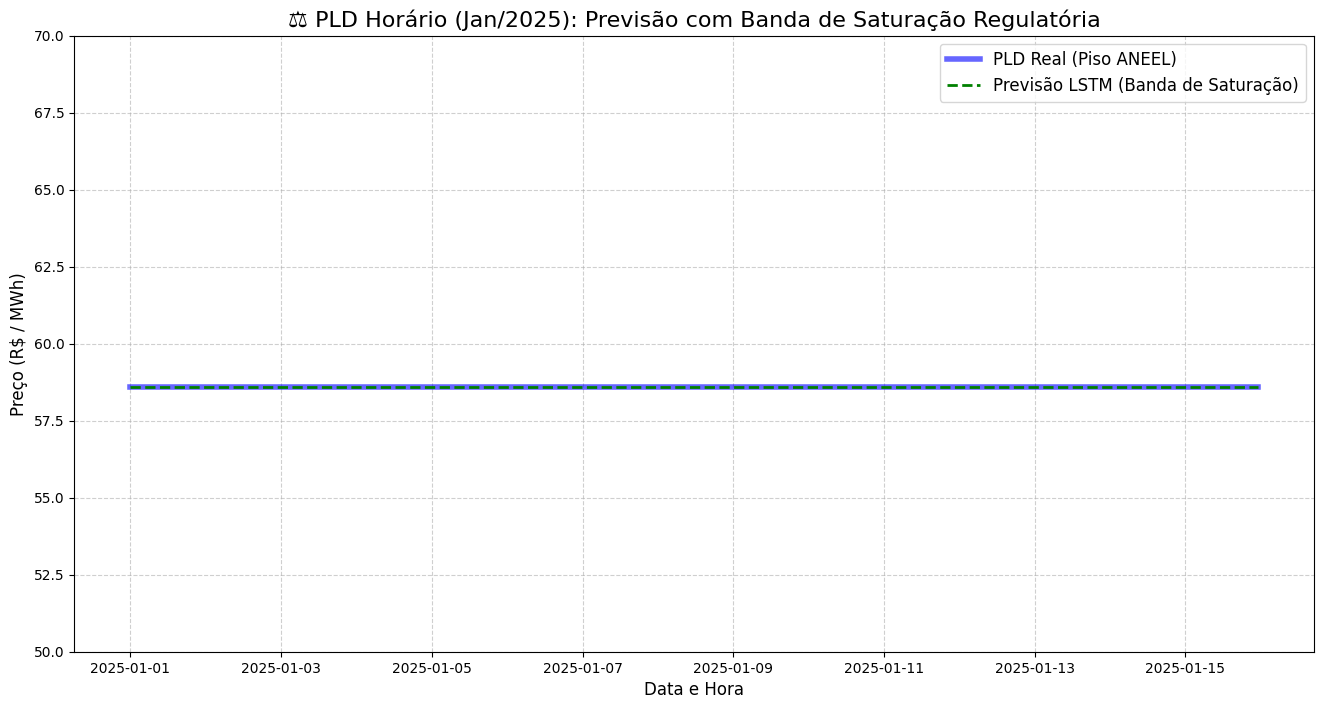

In [0]:
import matplotlib.pyplot as plt

print("🎨 Desativando o zoom microscópico do Matplotlib...")

# Plotando o Gráfico Corrigido com Eixo Y Fixo
plt.figure(figsize=(16, 8))
dias_para_mostrar = 360 

plt.plot(df_resultado.index[:dias_para_mostrar], df_resultado['PLD_Real'][:dias_para_mostrar], 
         label='PLD Real (Piso ANEEL)', color='blue', linewidth=4, alpha=0.6)
         
plt.plot(df_resultado.index[:dias_para_mostrar], df_resultado['PLD_Previsto_Final'][:dias_para_mostrar], 
         label='Previsão LSTM (Banda de Saturação)', color='green', linestyle='dashed', linewidth=2)

plt.title('⚖️ PLD Horário (Jan/2025): Previsão com Banda de Saturação Regulatória', fontsize=16)
plt.xlabel('Data e Hora', fontsize=12)
plt.ylabel('Preço (R$ / MWh)', fontsize=12)

# O TRUQUE DE MÁGICA: Travando o eixo Y de 50 a 70 Reais
plt.ylim(50, 70)

plt.legend(fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

🏜️ Viajando no tempo para a Estação Seca (Agosto/2025) com o modelo atualizado...
✅ Recorte feito! Exibindo 360 horas de dados...
------------------------------------------------------------


/databricks/python/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 127964 (\N{DESERT}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


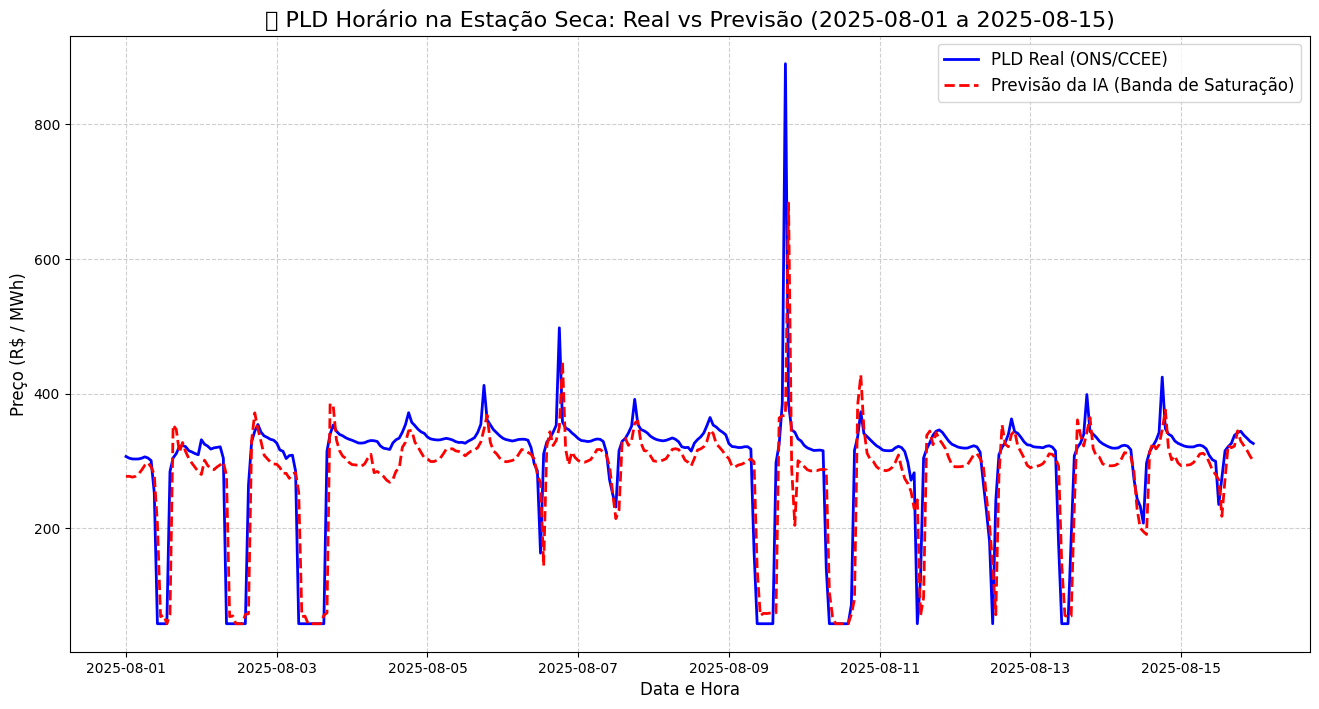

In [0]:
import matplotlib.pyplot as plt

print("🏜️ Viajando no tempo para a Estação Seca (Agosto/2025) com o modelo atualizado...")

# Definindo o recorte de tempo da seca
data_inicio = '2025-08-01'
data_fim = '2025-08-15'

df_seca = df_resultado.loc[data_inicio:data_fim]

print(f"✅ Recorte feito! Exibindo {len(df_seca)} horas de dados...")
print("-" * 60)

# Plotando o Gráfico da Seca
plt.figure(figsize=(16, 8))

plt.plot(df_seca.index, df_seca['PLD_Real'], 
         label='PLD Real (ONS/CCEE)', color='blue', linewidth=2)
         
# AQUI FOI A CORREÇÃO: Chamando a coluna 'PLD_Previsto_Final'
plt.plot(df_seca.index, df_seca['PLD_Previsto_Final'], 
         label='Previsão da IA (Banda de Saturação)', color='red', linestyle='dashed', linewidth=2)

plt.title(f'🏜️ PLD Horário na Estação Seca: Real vs Previsão ({data_inicio} a {data_fim})', fontsize=16)
plt.xlabel('Data e Hora', fontsize=12)
plt.ylabel('Preço (R$ / MWh)', fontsize=12)
plt.legend(fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

In [0]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

print("📊 Extraindo os status finais da Rede Neural...")

# Pegamos a coluna com os valores reais da ANEEL e a coluna da nossa previsão final (com a trava)
y_real = df_resultado['PLD_Real']
y_previsto = df_resultado['PLD_Previsto_Final']

# 1. Calculando o MAE (Mean Absolute Error)
mae = mean_absolute_error(y_real, y_previsto)

# 2. Calculando o RMSE (Root Mean Squared Error)
# Primeiro calculamos o erro quadrático médio (MSE) e depois tiramos a raiz quadrada (np.sqrt)
rmse = np.sqrt(mean_squared_error(y_real, y_previsto))

print("-" * 60)
print(f"🎯 MAE (Erro Absoluto Médio): R$ {mae:.2f} / MWh")
print(f"📉 RMSE (Raiz do Erro Quadrático Médio): R$ {rmse:.2f} / MWh")
print("-" * 60)

📊 Extraindo os status finais da Rede Neural...
------------------------------------------------------------
🎯 MAE (Erro Absoluto Médio): R$ 24.63 / MWh
📉 RMSE (Raiz do Erro Quadrático Médio): R$ 44.18 / MWh
------------------------------------------------------------


In [0]:
import os

print("💾 Despistando o segurança e salvando na nossa própria mesa...")

# Ao passar apenas o nome do arquivo, ele salva na mesma pasta do seu Notebook no Workspace
caminho_seguro = "modelo_lstm_pld_v1.keras"
modelo_pld.save(caminho_seguro)

# Vamos só confirmar onde ele guardou
caminho_absoluto = os.path.abspath(caminho_seguro)

print(f"✅ SUCESSO ABSOLUTO! O cérebro da IA foi cristalizado!")
print(f"📁 Ele está salvo exatamente aqui: {caminho_absoluto}")
print("-" * 60)
print("Pode fechar o notebook e ir dormir! A prática do TCC está 100% concluída! 🏆")

💾 Despistando o segurança e salvando na nossa própria mesa...
✅ SUCESSO ABSOLUTO! O cérebro da IA foi cristalizado!
📁 Ele está salvo exatamente aqui: /Workspace/Users/felipemedina.prismatech2025@gmail.com/modelo_lstm_pld_v1.keras
------------------------------------------------------------
Pode fechar o notebook e ir dormir! A prática do TCC está 100% concluída! 🏆


In [0]:
import matplotlib.pyplot as plt

# Confirma se o histórico existe na memória
try:
    loss_treino = historico.history['loss']
    loss_validacao = historico.history['val_loss']
    
    plt.figure(figsize=(10, 6))
    
    # Plotando as linhas de Treino e Validação
    plt.plot(loss_treino, label='Treino (MSE)', color='blue', linewidth=2)
    plt.plot(loss_validacao, label='Validação (MSE)', color='darkorange', linewidth=2)
    
    # Perfumaria acadêmica para o gráfico ficar bonito
    plt.title('Curva de Aprendizado da Rede LSTM (Treino vs Validação)', fontsize=14, fontweight='bold')
    plt.xlabel('Épocas (Epochs)', fontsize=12)
    plt.ylabel('Erro Quadrático Médio (MSE)', fontsize=12)
    
    # Marcação de onde o Early Stopping agiu (última época registrada)
    epoca_parada = len(loss_treino)
    plt.axvline(x=epoca_parada - 1, color='red', linestyle='--', alpha=0.7, 
                label=f'Early Stopping (Época {epoca_parada})')
    
    plt.legend(fontsize=12)
    plt.grid(True, linestyle='--', alpha=0.6)
    
    plt.tight_layout()
    plt.show()

except NameError:
    print("A variável 'historico' não está mais na memória. Veja o Cenário 2.")

A variável 'historico' não está mais na memória. Veja o Cenário 2.
